# Facial Emotion Detection — FER-2013

**Objective:** Classify facial expressions into 7 emotion classes using a custom CNN and ImageNet-pretrained VGG16 and ResNet50 models.

**Dataset:** FER-2013 — 48×48 grayscale facial images with 7 classes:
`Angry, Disgust, Fear, Happy, Sad, Surprise, Neutral`

**Models**
1. Custom CNN
2. VGG16 transfer learning + fine-tuning
3. ResNet50 transfer learning + fine-tuning

**Evaluation:** accuracy, precision, recall, F1-score, confusion matrix, training curves, and class-wise ROC-AUC.

> This notebook computes the results from the downloaded dataset. Do not put a numerical result such as 61% accuracy on the CV until the notebook has actually been run and the result verified.


In [1]:
# from google.colab import drive
# drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# Install dependencies (Google Colab)
!pip -q install tensorflow scikit-learn pandas matplotlib seaborn


## 1. Locate FER-2013 in Google Drive


In [ ]:
import os
from pathlib import Path

# Directly use the known path
DATA_PATH = "fer2013.csv"
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"File not found at {DATA_PATH}. Please place fer2013.csv in that location.")

print("Using:", DATA_PATH)


Using: /content/drive/MyDrive/Datasets/fer2013.csv


## 2. Imports and configuration

In [4]:
import os, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    roc_curve, auc, roc_auc_score
)
from sklearn.preprocessing import label_binarize

# Enable mixed precision for faster training on GPU
tf.keras.mixed_precision.set_global_policy('mixed_float16')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 48
NUM_CLASSES = 7
BATCH_SIZE = 64
EPOCHS_HEAD = 25          # increased from 20
EPOCHS_FINE = 8            # Reduced from 15

CLASS_NAMES = [
    "Angry", "Disgust", "Fear", "Happy",
    "Sad", "Surprise", "Neutral"
]

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Mixed precision policy:", tf.keras.mixed_precision.global_policy().name)


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: mixed_float16


## 3. Load and inspect FER-2013

In [5]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())
print(df.columns.tolist())


(30996, 3)


,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


['emotion', 'pixels', 'Usage']


emotion
0    4294
1     476
2    4420
3    7781
4    5221
5    3437
6    5367
Name: count, dtype: int64
emotion
0    0.138534
1    0.015357
2    0.142599
3    0.251032
4    0.168441
5    0.110885
6    0.173151
Name: proportion, dtype: float64


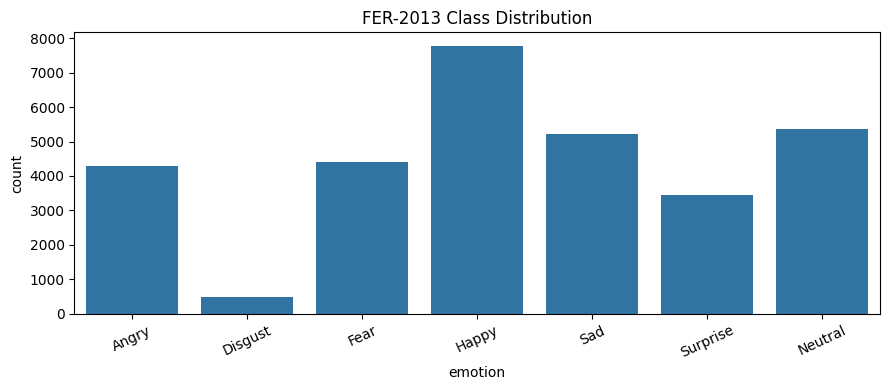

In [6]:
# Class distribution
print(df["emotion"].value_counts().sort_index())
print(df["emotion"].value_counts(normalize=True).sort_index())

plt.figure(figsize=(9, 4))
sns.countplot(data=df, x="emotion")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=25)
plt.title("FER-2013 Class Distribution")
plt.tight_layout()
plt.show()


## 4. Convert pixels and create train/validation/test splits

FER-2013 already provides a standard `Usage` split: Training, PublicTest, PrivateTest.


In [7]:
def parse_pixels(pixel_string):
    pixels = np.fromstring(pixel_string, dtype=np.uint8, sep=" ")
    if len(pixels) == IMG_SIZE * IMG_SIZE:
        return pixels.reshape(IMG_SIZE, IMG_SIZE)
    else:
        return None

parsed_pixels_series = df["pixels"].map(parse_pixels)
valid_indices = parsed_pixels_series.notna()

X = np.stack(parsed_pixels_series[valid_indices].values)
y = df["emotion"][valid_indices].astype(int).values

if not valid_indices.all():
    print(f"Warning: Dropped {len(df) - valid_indices.sum()} rows due to malformed pixel strings.")

X = X.astype("float32") / 255.0
X = X[..., np.newaxis]

# Use the standard Usage split
usage = df["Usage"][valid_indices].astype(str).str.lower()
train_mask = usage.str.contains("training")
val_mask   = usage.str.contains("public")
test_mask  = usage.str.contains("private")

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val     = X[val_mask], y[val_mask]
X_test, y_test   = X[test_mask], y[test_mask]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (28709, 48, 48, 1) (28709,)
Validation: (2286, 48, 48, 1) (2286,)
Test: (0, 48, 48, 1) (0,)


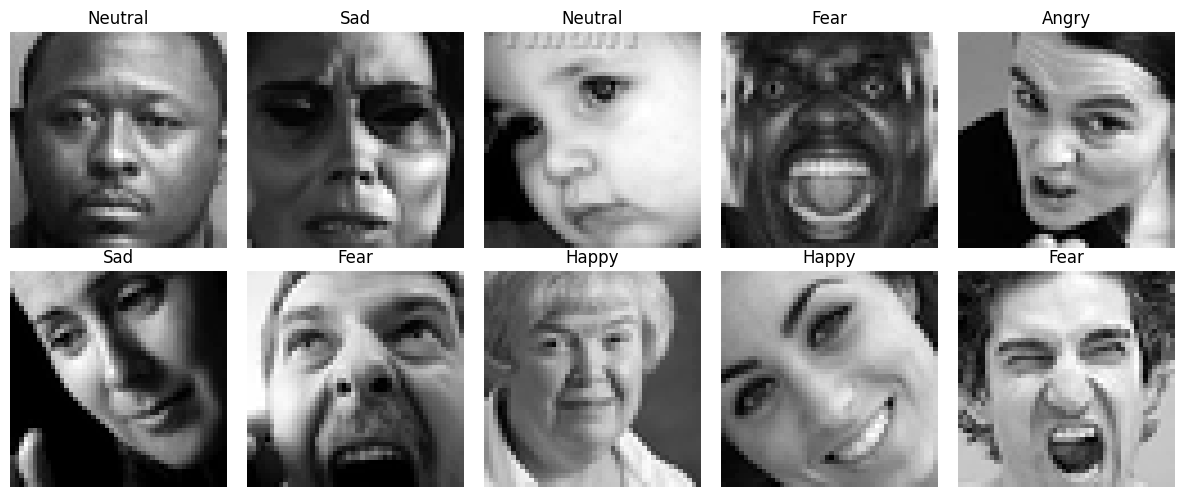

In [8]:
# Display sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.ravel(), np.random.choice(len(X_train), 10, replace=False)):
    ax.imshow(X_train[idx].squeeze(), cmap="gray")
    ax.set_title(CLASS_NAMES[y_train[idx]])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Handle class imbalance

Class weights are calculated from the training set and supplied to model training. This prevents frequent classes such as `Happy` from dominating the optimization.


In [9]:
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
CLASS_WEIGHTS = dict(zip(classes, weights))

print({CLASS_NAMES[k]: round(v, 3) for k, v in CLASS_WEIGHTS.items()})


{'Angry': np.float64(1.027), 'Disgust': np.float64(9.407), 'Fear': np.float64(1.001), 'Happy': np.float64(0.568), 'Sad': np.float64(0.849), 'Surprise': np.float64(1.293), 'Neutral': np.float64(0.826)}


## 6. Data augmentation

In [10]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.08, 0.08),
], name="augmentation")


## 7. Custom CNN

In [11]:
def build_custom_cnn():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = augmentation(inputs)

    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.50)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return models.Model(inputs, outputs, name="Custom_CNN")

custom_cnn = build_custom_cnn()
custom_cnn.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
custom_cnn.summary()


Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 324,071 (1.24 MB)

 Trainable params: 322,663 (1.23 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [12]:
def train_model(model, name, epochs=EPOCHS_HEAD):
    os.makedirs("results", exist_ok=True)
    os.makedirs("models", exist_ok=True)

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),  # reduced patience
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
        ModelCheckpoint(
            f"models/{name}.keras",
            monitor="val_accuracy",
            save_best_only=True
        )
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHTS,
        callbacks=callbacks,
        verbose=1
    )
    return history

history_cnn = train_model(custom_cnn, "custom_cnn")


Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 43s 47ms/step - accuracy: 0.1590 - loss: 2.3659 - val_accuracy: 0.1662 - val_loss: 1.9916 - learning_rate: 0.0010
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.1725 - loss: 2.0280 - val_accuracy: 0.0201 - val_loss: 2.4611 - learning_rate: 0.0010
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.2055 - loss: 1.9166 - val_accuracy: 0.2747 - val_loss: 1.8248 - learning_rate: 0.0010
Epoch 4/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 23s 38ms/step - accuracy: 0.2773 - loss: 1.7883 - val_accuracy: 0.3268 - val_loss: 1.7063 - learning_rate: 0.0010
Epoch 5/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.3471 - loss: 1.6694 - val_accuracy: 0.4239 - val_loss: 1.4748 - learning_rate: 0.0010
Epoch 6/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.3975 - loss: 1.5737 - val_accuracy: 0.4449 - val_loss: 1.4457 - learning_rate: 0.0010
Epoch 7/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.4247 - l

## 8. Training curves — Custom CNN

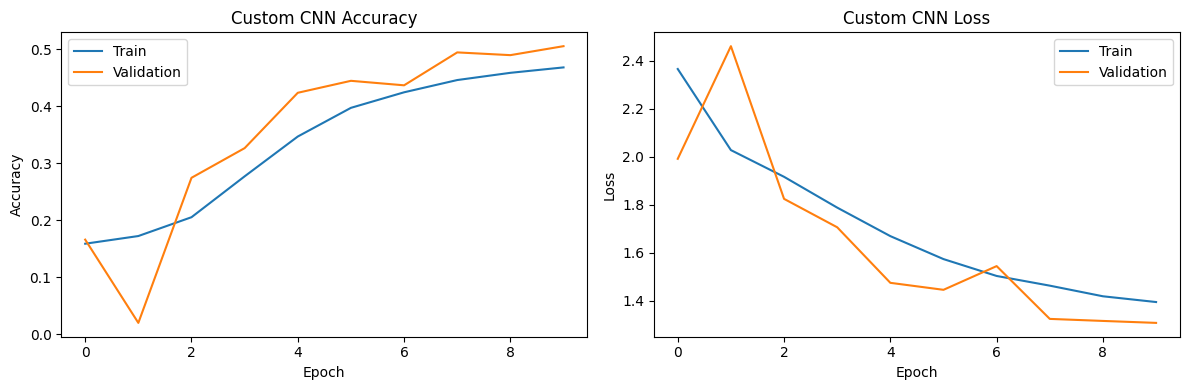

In [13]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history["accuracy"], label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title(f"{title} Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(history.history["loss"], label="Train")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title(f"{title} Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history_cnn, "Custom CNN")


## 9. Prepare grayscale images for pretrained ImageNet models

VGG16 and ResNet50 expect 3-channel images. The grayscale FER-2013 images are therefore replicated across the RGB channels.

The input is resized to 96×96 to reduce computational cost. You can use 224×224 if GPU memory and training time permit.


In [14]:
PRETRAIN_SIZE = 96

def to_rgb_resized(images):
    x = tf.image.resize(images, (PRETRAIN_SIZE, PRETRAIN_SIZE))
    return tf.image.grayscale_to_rgb(x).numpy()

X_train_rgb = to_rgb_resized(X_train)
X_val_rgb = to_rgb_resized(X_val)
X_test_rgb = to_rgb_resized(X_test)

print(X_train_rgb.shape)


(28709, 96, 96, 3)


## 10. VGG16 transfer learning + fine-tuning

In [15]:
def build_vgg16():
    base = VGG16(
        include_top=False,
        weights="imagenet",
        input_shape=(PRETRAIN_SIZE, PRETRAIN_SIZE, 3)
    )
    base.trainable = False

    inputs = layers.Input(shape=(PRETRAIN_SIZE, PRETRAIN_SIZE, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.05)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return models.Model(inputs, outputs, name="VGG16_FER")

vgg16_model = build_vgg16()
vgg16_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
vgg16_model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 22s 0us/step


Model: "VGG16_FER"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,839 (56.64 MB)

 Trainable params: 133,639 (522.03 KB)

 Non-trainable params: 14,715,200 (56.13 MB)

In [ ]:
def train_pretrained_head(model, Xtr, Xv, name):
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
        ModelCheckpoint(f"models/{name}_head.keras",
                        monitor="val_accuracy", save_best_only=True)
    ]

    return model.fit(
        Xtr, y_train,
        validation_data=(Xv, y_val),
        epochs=EPOCHS_HEAD,
        batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHTS,
        callbacks=callbacks,
        verbose=1
    )

history_vgg_head = train_pretrained_head(
    vgg16_model, X_train_rgb, X_val_rgb, "vgg16"
)


In [ ]:
# Fine-tune the last VGG16 convolutional block
base_vgg = vgg16_model.get_layer("vgg16")
base_vgg.trainable = True

for layer in base_vgg.layers:
    layer.trainable = layer.name.startswith("block5")

vgg16_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_vgg_fine = train_pretrained_head(
    vgg16_model, X_train_rgb, X_val_rgb, "vgg16_finetuned"
)


## 11. ResNet50 transfer learning + fine-tuning

In [ ]:
def build_resnet50():
    base = ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(PRETRAIN_SIZE, PRETRAIN_SIZE, 3)
    )
    base.trainable = False

    inputs = layers.Input(shape=(PRETRAIN_SIZE, PRETRAIN_SIZE, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.05)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return models.Model(inputs, outputs, name="ResNet50_FER")

resnet50_model = build_resnet50()
resnet50_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
resnet50_model.summary()


In [ ]:
history_resnet_head = train_pretrained_head(
    resnet50_model, X_train_rgb, X_val_rgb, "resnet50"
)


In [ ]:
# Fine-tune the final ResNet stages.
base_resnet = resnet50_model.get_layer("resnet50")
base_resnet.trainable = True

# Keep BatchNorm layers frozen for more stable fine-tuning.
for layer in base_resnet.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = layer.name.startswith(("conv5_", "post_"))

resnet50_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_resnet_fine = train_pretrained_head(
    resnet50_model, X_train_rgb, X_val_rgb, "resnet50_finetuned"
)


## 12. Evaluation utilities

In [ ]:
def evaluate_model(model, X_eval, y_eval, name):
    probs = model.predict(X_eval, batch_size=BATCH_SIZE, verbose=0)
    preds = probs.argmax(axis=1)

    acc = accuracy_score(y_eval, preds)
    report = classification_report(
        y_eval, preds,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    print(f"\n{name} Accuracy: {acc:.4f}")
    print(classification_report(
        y_eval, preds,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(y_eval, preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
    )
    plt.title(f"{name} — Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return {
        "model": name,
        "accuracy": acc,
        "precision_macro": report["macro avg"]["precision"],
        "recall_macro": report["macro avg"]["recall"],
        "f1_macro": report["macro avg"]["f1-score"],
        "precision_weighted": report["weighted avg"]["precision"],
        "recall_weighted": report["weighted avg"]["recall"],
        "f1_weighted": report["weighted avg"]["f1-score"],
        "probs": probs,
        "preds": preds,
        "report": report
    }


## 13. Evaluate all three models

In [ ]:
results = []

res_cnn = evaluate_model(custom_cnn, X_test, y_test, "Custom CNN")
results.append(res_cnn)

res_vgg = evaluate_model(vgg16_model, X_test_rgb, y_test, "VGG16 Fine-tuned")
results.append(res_vgg)

res_resnet = evaluate_model(resnet50_model, X_test_rgb, y_test, "ResNet50 Fine-tuned")
results.append(res_resnet)


In [ ]:
comparison = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ["probs", "preds", "report"]}
    for r in results
]).sort_values("accuracy", ascending=False)

display(comparison.style.format({
    "accuracy": "{:.4f}",
    "precision_macro": "{:.4f}",
    "recall_macro": "{:.4f}",
    "f1_macro": "{:.4f}",
    "precision_weighted": "{:.4f}",
    "recall_weighted": "{:.4f}",
    "f1_weighted": "{:.4f}"
}))
comparison.to_csv("results/model_comparison.csv", index=False)


## 14. Class-wise ROC-AUC for the best model

In [ ]:
best_result = max(results, key=lambda r: r["accuracy"])
best_name = best_result["model"]
best_probs = best_result["probs"]

y_test_bin = label_binarize(y_test, classes=np.arange(NUM_CLASSES))

plt.figure(figsize=(9, 7))

auc_values = {}
for i, class_name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], best_probs[:, i])
    class_auc = auc(fpr, tpr)
    auc_values[class_name] = class_auc
    plt.plot(fpr, tpr, label=f"{class_name} (AUC={class_auc:.3f})")

macro_auc = roc_auc_score(
    y_test_bin, best_probs, multi_class="ovr", average="macro"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"{best_name} — One-vs-Rest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

print("Macro ROC-AUC:", round(macro_auc, 4))
print("Class-wise AUC:", {k: round(v, 4) for k, v in auc_values.items()})


## 15. Save final metrics

In [ ]:
metrics = comparison.copy()
metrics["macro_roc_auc"] = np.nan
metrics.loc[metrics["model"] == best_name, "macro_roc_auc"] = macro_auc

metrics.to_csv("results/final_metrics.csv", index=False)

print("Best model:", best_name)
print("Best test accuracy:", f"{best_result['accuracy']:.4%}")
print("Best macro ROC-AUC:", f"{macro_auc:.4f}")


## 16. Generate a CV-ready result summary

Run this cell only after completing training. It uses the **actual measured results** from the test set.


In [ ]:
best_acc = best_result["accuracy"]
best_f1 = best_result["report"]["macro avg"]["f1-score"]

print(f"""CV-ready summary:

- Developed a CNN-based facial emotion classifier for 7 emotion categories using the FER-2013 grayscale image dataset.
- Built and compared a custom CNN with ImageNet-pretrained VGG16 and ResNet50 using data augmentation, Batch Normalization, Dropout, class weighting, and fine-tuning.
- Best model: {best_name}; achieved {best_acc:.2%} test accuracy and {best_f1:.2%} macro F1-score, with performance evaluated using confusion matrices and class-wise ROC-AUC.
""")


## 17. Download results

After running the notebook, the following files are available under `results/`:
- `model_comparison.csv`
- `final_metrics.csv`
- saved model checkpoints under `models/`

### Recommended CV practice
Use the exact test accuracy and metrics printed above. Do not report the previously mentioned **61%** unless the actual run produces approximately that value.
